In [1]:
%load_ext autoreload
%autoreload 2

# Compare variance for ESM4 and ESM2M

In [3]:
import xarray as xr
import esm4ppe
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import matplotlib as mpl
import xesmf
from dask.diagnostics import ProgressBar
import numpy as np
from functions import *

ModuleNotFoundError: No module named 'functions'

## Load data

In [4]:
basedir = '/projects/SOCCOM/graemem/projects/esm4_ppe'
# load esm2m
localdir = '/data/processed/esm2m/variance'
ev_esm2m = xr.open_mfdataset('/'.join([basedir,localdir,'ensemble','ocean.*.nc']))
cv_esm2m = xr.open_mfdataset('/'.join([basedir,localdir,'control','ocean.*.nc']))
# load esm4
ev_esm4 = esm4ppe.open_ensemblevariance('ocean','monthly',groupby='month').isel(month=0)
cv_esm4 = esm4ppe.open_controlvariance('ocean','monthly')
# load esm4 static
static = esm4ppe.open_static('intpp','monthly')

/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


In [5]:
names = {'esm4':{'intpp':'intpp','tos':'tos','MLD_003':'MLD_003','geolat':'geolat','geolon':'geolon','areacello':'areacello'},
         'esm2m':{'intpp':'NPP','tos':'sst','MLD_003':'mld','geolat':'geolat_t','geolon':'geolon_t','areacello':'area_t'}}
colors = {'esm4':'tab:blue',
          'esm2m':'tab:orange'}
linestyles = {'esm2m':':',
              'esm4':'-'}
maskers = {'esm2m':'.',
           'esm4':'s'}
colors_v = {'intpp':'tab:green',
            'tos':'tab:blue',
            'MLD_003':'tab:orange'}

## Interpolate esm2m onto esm4

In [6]:
ev_esm2m_n = ev_esm2m.rename({'xt_ocean':'xh','yt_ocean':'yh'})
cv_esm2m_n = cv_esm2m.rename({'xt_ocean':'xh','yt_ocean':'yh'})

static_esm4 = static.rename({'geolon':'lon','geolat':'lat'})

In [7]:
regrid_2m24 = xesmf.Regridder(ev_esm2m_n,static_esm4,periodic=True,method='bilinear')

In [8]:
ev_esm2m_r = regrid_2m24(ev_esm2m_n)
cv_esm2m_r = regrid_2m24(cv_esm2m_n)
ev_esm2m_r

<xarray.Dataset>
Dimensions:  (lead: 120, yh: 576, xh: 720)
Coordinates:
  * lead     (lead) int64 1 2 3 4 5 6 7 8 9 ... 113 114 115 116 117 118 119 120
  * xh       (xh) float64 -299.8 -299.2 -298.8 -298.2 ... 58.75 59.25 59.75
  * yh       (yh) float64 -77.91 -77.72 -77.54 -77.36 ... 89.47 89.68 89.89
Data variables:
    NPP      (lead, yh, xh) float32 dask.array<chunksize=(120, 200, 360), meta=np.ndarray>
Attributes:
    regrid_method:  bilinear

## Global averages

In [13]:
cvg_esm2m = cv_esm2m_r[names['esm2m']['intpp']].weighted(static['areacello'].fillna(0)).mean(['xh','yh'])
evg_esm2m = ev_esm2m_r[names['esm2m']['intpp']].weighted(static['areacello'].fillna(0)).mean(['xh','yh'])

cvg_esm4 = cv_esm4[names['esm4']['intpp']].weighted(static['areacello'].fillna(0)).mean(['xh','yh'])
evg_esm4 = ev_esm4[names['esm4']['intpp']].weighted(static['areacello'].fillna(0)).mean(['xh','yh'])

NameError: name 'save_fig' is not defined

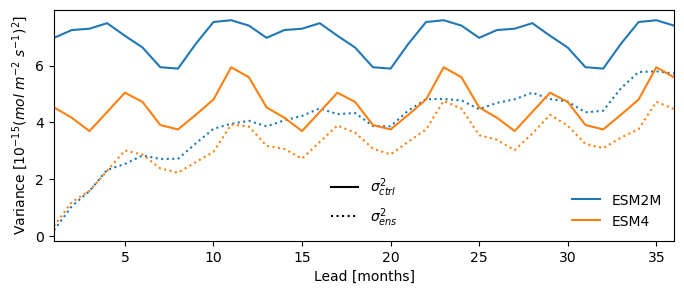

In [43]:
import matplotlib.lines as mlines
fig,ax = plt.subplots(figsize=(8,3))
leads = np.arange(1,37)
im1, = ax.plot(leads,1e15*cvg_esm2m.sel(lead=np.tile(np.arange(1,13),int(len(leads)/12))),color='tab:blue',label='ESM2M')
im2, = ax.plot(leads,1e15*evg_esm2m.sel(lead=leads),color='tab:blue',linestyle=':')
ax.plot(leads,1e15*cvg_esm4.sel(lead=np.tile(np.arange(1,13),int(len(leads)/12))),color='tab:orange',label='ESM4')
ax.plot(leads,1e15*evg_esm4.sel(lead=leads),color='tab:orange',linestyle=':')

leg1=ax.legend(frameon=False,loc='lower right')
ax.add_artist(leg1)
handles = [mlines.Line2D([], [], linestyle=linestyle, color='k') for linestyle in ['-', ':']]
ax.legend(handles,[r'$\sigma^2_{ctrl}$',r'$\sigma^2_{ens}$'],frameon=False,loc='lower center')
ax.set_xlim(leads[0],leads[-1])
ax.set_ylabel(r'Variance [$10^{-15}(mol\ m^{-2}\ s^{-1})^2$]')
ax.set_xlabel(r'Lead [months]')

save_fig(fig,'fig.esm4-esm2m-comparison_variance.globalmean.'+variable)